## 1. Environment


In [1]:
!pip install -q pandas numpy matplotlib scikit-learn xgboost

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Rdkit_10_修改.csv to Rdkit_10_修改.csv


In [3]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
import sklearn, xgboost
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)


pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1
xgboost: 3.4.1


## 2. Configuration

In [4]:
# The ZIP package contains this CSV in ./data/.
DATA_FILE = Path("data") / "Rdkit_10_修改.csv"
if not DATA_FILE.exists():
    # Fallback if the CSV is placed beside the notebook.
    DATA_FILE = Path("Rdkit_10_修改.csv")

TARGET_COL = "PCE"
SMILES_COL_CANDIDATES = ["smile", "smiles", "SMILES"]

# Pilot settings. After confirming the notebook runs correctly, increase to
# 10 or 20 repeats for a more stable final diagnostic.
N_SPLITS = 5
N_REPEATS = 5
TRAIN_SIZE_FRACTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]
BASE_SEED = 2101

# Fixed corrected RDKit-XGBoost hyperparameters (Table S6 in the current SI).
# Additional settings: tree_method / random_state / n_jobs are fixed for reproducibility.
XGB_PARAMS = {
    "n_estimators": 430,
    "colsample_bytree": 0.05,
    "gamma": 0.5,
    "learning_rate": 0.9,
    "max_depth": 6,
    "min_child_weight": 5,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "subsample": 0.9,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 2026,
    "n_jobs": 1,
    "verbosity": 0,
}

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Data file:", DATA_FILE.resolve())
print("Repeats:", N_REPEATS, "| folds:", N_SPLITS)
print("Training fractions:", TRAIN_SIZE_FRACTIONS)


Data file: /content/Rdkit_10_修改.csv
Repeats: 5 | folds: 5
Training fractions: [0.2, 0.4, 0.6, 0.8, 1.0]


## 3. Load and audit the corrected dataset

In [5]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE}. Keep the supplied data folder beside the notebook, "
        "or update DATA_FILE to the correct CSV path."
    )

df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")
df.columns = [str(c).strip() for c in df.columns]

smiles_col = next((c for c in SMILES_COL_CANDIDATES if c in df.columns), None)
if smiles_col is None:
    raise ValueError(f"Cannot identify the SMILES column. Columns include: {df.columns[:10].tolist()}")
if TARGET_COL not in df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found.")

# Preserve the exact SMILES strings used in the existing molecule-wise analysis.
if df[smiles_col].isna().any():
    raise ValueError("Missing SMILES/group identifiers were found.")
groups = df[smiles_col].astype(str).str.strip().to_numpy()
if np.any(pd.Series(groups).str.len().to_numpy() == 0):
    raise ValueError("Empty SMILES/group identifiers were found.")

# Use all numeric columns except the target. SMILES is used only for grouping.
non_feature_cols = [smiles_col, TARGET_COL]
feature_frame = df.drop(columns=non_feature_cols)
non_numeric_cols = feature_frame.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_cols:
    raise ValueError(
        "Unexpected non-numeric predictor columns were found: " + str(non_numeric_cols) +
        ". Please inspect the source CSV rather than silently dropping them."
    )

X = feature_frame.astype(float)
y = pd.to_numeric(df[TARGET_COL], errors="coerce").to_numpy(dtype=float)

if X.isna().any().any() or np.isnan(y).any():
    raise ValueError("Missing/non-numeric predictor or target values were found.")
if not np.isfinite(X.to_numpy()).all() or not np.isfinite(y).all():
    raise ValueError("Infinite values were found in predictors or target.")

print("Dataset shape:", df.shape)
print("Records:", len(df))
print("Unique exact-SMILES identities:", pd.Series(groups).nunique())
print("Predictors:", X.shape[1])
print("PCE range:", (float(np.min(y)), float(np.max(y))))
print("Missing values:", int(df.isna().sum().sum()))

if len(df) != 99 or pd.Series(groups).nunique() != 57 or X.shape[1] != 220:
    warnings.warn(
        "The loaded file does not match the expected audit (99 records, 57 exact SMILES, "
        "220 predictors). Check that the corrected RDKit_10 file was selected."
    )

# Record-level and molecule-level distribution audit.
record_counts = pd.Series(groups).value_counts().sort_values(ascending=False)
print("\nRecords per molecule (count distribution):")
print(record_counts.value_counts().sort_index().rename_axis("records_per_molecule").to_frame("number_of_molecules"))


Dataset shape: (99, 222)
Records: 99
Unique exact-SMILES identities: 57
Predictors: 220
PCE range: (10.24, 25.52)
Missing values: 0

Records per molecule (count distribution):
                      number_of_molecules
records_per_molecule                     
1                                      42
2                                       2
3                                       6
4                                       4
5                                       1
7                                       2


## 4. Split generators


In [6]:
def repeated_record_splits(n_samples, n_splits=5, n_repeats=5, seed=2101):
    """Repeated shuffled K-fold splits at the device-record level."""
    all_idx = np.arange(n_samples)
    for repeat in range(n_repeats):
        rng = np.random.default_rng(seed + repeat)
        shuffled = rng.permutation(all_idx)
        test_folds = np.array_split(shuffled, n_splits)
        for fold, test_idx in enumerate(test_folds, start=1):
            train_idx = np.setdiff1d(all_idx, test_idx, assume_unique=False)
            yield repeat + 1, fold, train_idx, test_idx


def repeated_group_splits(group_values, n_splits=5, n_repeats=5, seed=2101):
    """Repeated approximately record-balanced folds with exact-SMILES groups intact.

    A greedy assignment distributes larger groups first to the currently smallest
    fold. This reduces avoidable imbalance in the number of device records while
    never splitting a molecule across folds.
    """
    group_values = np.asarray(group_values, dtype=str)
    unique_groups = np.unique(group_values)
    if len(unique_groups) < n_splits:
        raise ValueError("Number of unique molecules is smaller than n_splits.")

    all_idx = np.arange(len(group_values))
    group_counts = {g: int(np.sum(group_values == g)) for g in unique_groups}

    for repeat in range(n_repeats):
        rng = np.random.default_rng(seed + repeat)
        shuffled_groups = rng.permutation(unique_groups)
        # Stable descending sort: the prior random permutation randomizes ties.
        ordered_groups = sorted(shuffled_groups, key=lambda g: group_counts[g], reverse=True)
        test_group_folds = [[] for _ in range(n_splits)]
        fold_record_counts = np.zeros(n_splits, dtype=int)

        for group in ordered_groups:
            lightest = np.flatnonzero(fold_record_counts == fold_record_counts.min())
            chosen_fold = int(rng.choice(lightest))
            test_group_folds[chosen_fold].append(group)
            fold_record_counts[chosen_fold] += group_counts[group]

        for fold, test_groups in enumerate(test_group_folds, start=1):
            test_mask = np.isin(group_values, test_groups)
            test_idx = all_idx[test_mask]
            train_idx = all_idx[~test_mask]

            # Strict group separation check.
            overlap = set(group_values[train_idx]).intersection(set(group_values[test_idx]))
            if overlap:
                raise RuntimeError("Group leakage detected in molecule-wise split.")
            yield repeat + 1, fold, train_idx, test_idx


## 5. Model and metric functions

In [7]:
def make_model(seed=2026):
    params = dict(XGB_PARAMS)
    params["random_state"] = seed
    return Pipeline([
        ("scaler", StandardScaler()),
        ("xgb", XGBRegressor(**params)),
    ])


def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
    }


## 6. Run the learning-curve analysis


In [8]:
def run_learning_curve(X, y, group_values, split_mode):
    X_array = X.to_numpy(dtype=float)
    y_array = np.asarray(y, dtype=float)
    group_values = np.asarray(group_values, dtype=str)

    if split_mode == "record-wise":
        split_iter = repeated_record_splits(
            len(y_array), N_SPLITS, N_REPEATS, BASE_SEED
        )
    elif split_mode == "molecule-wise":
        split_iter = repeated_group_splits(
            group_values, N_SPLITS, N_REPEATS, BASE_SEED
        )
    else:
        raise ValueError("split_mode must be 'record-wise' or 'molecule-wise'.")

    rows = []
    for repeat, fold, outer_train_idx, outer_test_idx in split_iter:
        rng = np.random.default_rng(BASE_SEED + repeat * 100 + fold)

        if split_mode == "record-wise":
            ordered_units = rng.permutation(outer_train_idx)
            n_units_total = len(ordered_units)
        else:
            train_groups = np.unique(group_values[outer_train_idx])
            ordered_units = rng.permutation(train_groups)
            n_units_total = len(ordered_units)

        for fraction in TRAIN_SIZE_FRACTIONS:
            n_units = max(2, int(np.ceil(fraction * n_units_total)))
            n_units = min(n_units, n_units_total)
            selected_units = ordered_units[:n_units]

            if split_mode == "record-wise":
                fit_idx = selected_units.astype(int)
            else:
                fit_idx = outer_train_idx[np.isin(group_values[outer_train_idx], selected_units)]

            # A new model is fitted for each learning-curve point.
            model = make_model(seed=2026)
            model.fit(X_array[fit_idx], y_array[fit_idx])

            pred_train = model.predict(X_array[fit_idx])
            pred_valid = model.predict(X_array[outer_test_idx])
            train_metrics = regression_metrics(y_array[fit_idx], pred_train)
            valid_metrics = regression_metrics(y_array[outer_test_idx], pred_valid)

            train_group_count = len(np.unique(group_values[fit_idx]))
            valid_group_count = len(np.unique(group_values[outer_test_idx]))

            rows.append({
                "split_mode": split_mode,
                "repeat": repeat,
                "fold": fold,
                "train_fraction": fraction,
                "n_train_records": len(fit_idx),
                "n_train_molecules": train_group_count,
                "n_valid_records": len(outer_test_idx),
                "n_valid_molecules": valid_group_count,
                "train_RMSE": train_metrics["RMSE"],
                "valid_RMSE": valid_metrics["RMSE"],
                "train_MAE": train_metrics["MAE"],
                "valid_MAE": valid_metrics["MAE"],
                "train_R2": train_metrics["R2"],
                "valid_R2": valid_metrics["R2"],
            })

        print(f"{split_mode}: completed repeat {repeat}, fold {fold}")

    return pd.DataFrame(rows)


In [9]:
# Run the two prediction tasks separately.
record_results = run_learning_curve(X, y, groups, "record-wise")
molecule_results = run_learning_curve(X, y, groups, "molecule-wise")

raw_results = pd.concat([record_results, molecule_results], ignore_index=True)
raw_path = OUTPUT_DIR / "learning_curve_raw_metrics.csv"
raw_results.to_csv(raw_path, index=False, encoding="utf-8-sig")
print("Saved:", raw_path.resolve())
print("Raw result shape:", raw_results.shape)
raw_results.head()


record-wise: completed repeat 1, fold 1
record-wise: completed repeat 1, fold 2
record-wise: completed repeat 1, fold 3
record-wise: completed repeat 1, fold 4
record-wise: completed repeat 1, fold 5
record-wise: completed repeat 2, fold 1
record-wise: completed repeat 2, fold 2
record-wise: completed repeat 2, fold 3
record-wise: completed repeat 2, fold 4
record-wise: completed repeat 2, fold 5
record-wise: completed repeat 3, fold 1
record-wise: completed repeat 3, fold 2
record-wise: completed repeat 3, fold 3
record-wise: completed repeat 3, fold 4
record-wise: completed repeat 3, fold 5
record-wise: completed repeat 4, fold 1
record-wise: completed repeat 4, fold 2
record-wise: completed repeat 4, fold 3
record-wise: completed repeat 4, fold 4
record-wise: completed repeat 4, fold 5
record-wise: completed repeat 5, fold 1
record-wise: completed repeat 5, fold 2
record-wise: completed repeat 5, fold 3
record-wise: completed repeat 5, fold 4
record-wise: completed repeat 5, fold 5


,split_mode,repeat,fold,train_fraction,n_train_records,n_train_molecules,n_valid_records,n_valid_molecules,train_RMSE,valid_RMSE,train_MAE,valid_MAE,train_R2,valid_R2
0,record-wise,1,1,0.2,16,14,20,19,0.364396,4.586935,0.288360,3.541311,0.988835,-0.843659
1,record-wise,1,1,0.4,32,24,20,19,0.470590,3.457667,0.284742,2.455349,0.974413,-0.047615
2,record-wise,1,1,0.6,48,33,20,19,0.622848,3.223954,0.361348,2.437886,0.959253,0.089221
3,record-wise,1,1,0.8,64,42,20,19,0.585272,2.500001,0.358509,1.997783,0.967185,0.452334
4,record-wise,1,1,1.0,79,49,20,19,0.550957,2.130781,0.355738,1.546219,0.971044,0.602156


## 7. Summarize repeated-split results


In [10]:
metric_cols = [
    "train_RMSE", "valid_RMSE", "train_MAE", "valid_MAE", "train_R2", "valid_R2"
]
summary_rows = []
for (split_mode, fraction), part in raw_results.groupby(["split_mode", "train_fraction"]):
    row = {
        "split_mode": split_mode,
        "train_fraction": fraction,
        "n_train_records_mean": part["n_train_records"].mean(),
        "n_train_records_sd": part["n_train_records"].std(ddof=1),
        "n_train_molecules_mean": part["n_train_molecules"].mean(),
        "n_valid_records_mean": part["n_valid_records"].mean(),
        "n_valid_molecules_mean": part["n_valid_molecules"].mean(),
        "n_splits_observed": len(part),
    }
    for col in metric_cols:
        row[f"{col}_mean"] = part[col].mean()
        row[f"{col}_sd"] = part[col].std(ddof=1)
        row[f"{col}_p025"] = part[col].quantile(0.025)
        row[f"{col}_p975"] = part[col].quantile(0.975)
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows).sort_values(["split_mode", "train_fraction"])
summary_path = OUTPUT_DIR / "learning_curve_summary.csv"
summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
print("Saved:", summary_path.resolve())
summary[[
    "split_mode", "train_fraction", "n_train_records_mean", "n_train_molecules_mean",
    "train_RMSE_mean", "valid_RMSE_mean", "train_R2_mean", "valid_R2_mean"
]]


Saved: /content/results/learning_curve_summary.csv


,split_mode,train_fraction,n_train_records_mean,n_train_molecules_mean,train_RMSE_mean,valid_RMSE_mean,train_R2_mean,valid_R2_mean
0,molecule-wise,0.2,16.04,9.52,0.707604,3.589197,0.912925,-0.405203
1,molecule-wise,0.4,32.68,18.52,0.562107,3.558870,0.965630,-0.397743
2,molecule-wise,0.6,47.56,27.60,0.553559,3.581005,0.969986,-0.391718
3,molecule-wise,0.8,64.28,36.60,0.569008,3.242033,0.968882,-0.095733
4,molecule-wise,1.0,79.20,45.60,0.536279,3.129563,0.972799,-0.027506
5,record-wise,0.2,16.00,14.36,0.443713,3.487909,0.978568,-0.326333
6,record-wise,0.4,32.00,24.32,0.452313,3.250924,0.979819,-0.184493
7,record-wise,0.6,48.00,33.76,0.489294,2.850998,0.976371,0.081419
8,record-wise,0.8,64.00,41.84,0.503343,2.588137,0.975474,0.247184
9,record-wise,1.0,79.20,48.52,0.509442,2.344698,0.975235,0.406548


## 8. Plot learning curves

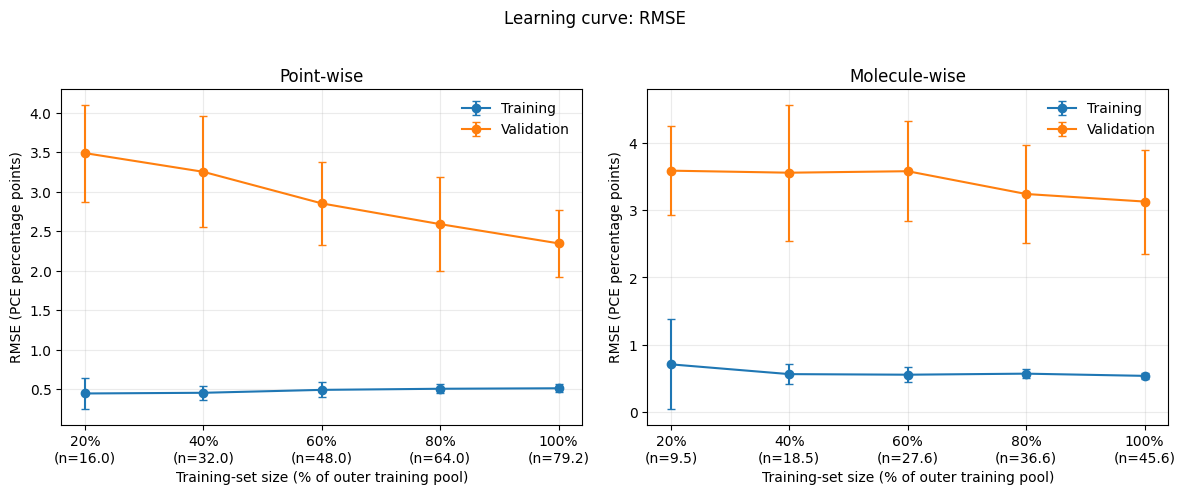

Saved: /content/results/learning_curve_RMSE.png


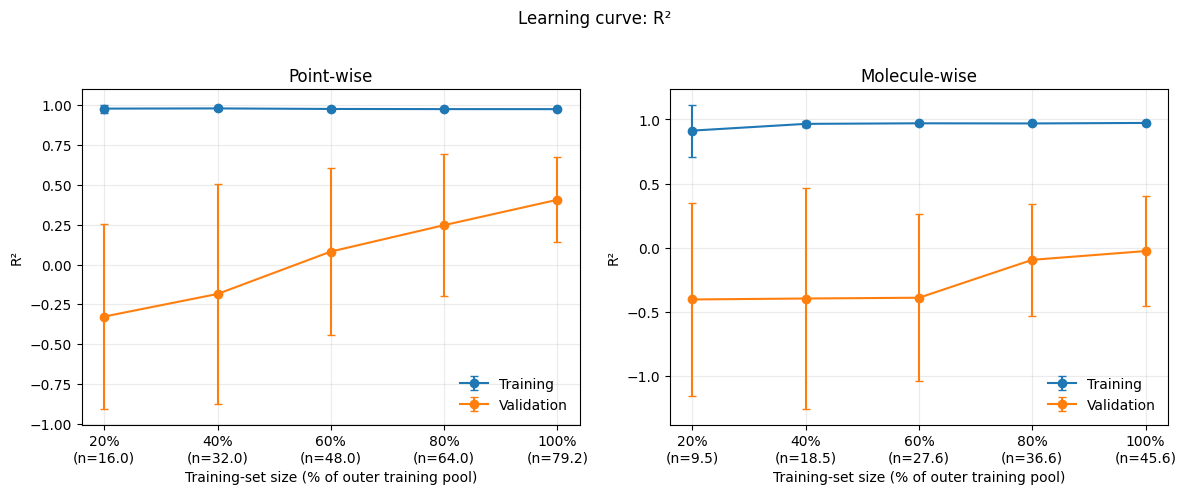

Saved: /content/results/learning_curve_R2.png


In [11]:
def plot_learning_curve_metric(summary_df, metric, ylabel, filename):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.8),
        sharey=False
    )

    # Internal split names remain unchanged.
    # Only the displayed labels are updated.
    modes = [
        ("record-wise", "Point-wise"),
        ("molecule-wise", "Molecule-wise")
    ]

    for ax, (mode, display_name) in zip(axes, modes):

        sub = summary_df[
            summary_df["split_mode"] == mode
        ].sort_values("train_fraction")

        x = sub["train_fraction"].to_numpy() * 100

        # Training and validation curves
        for label, prefix in [
            ("Training", "train"),
            ("Validation", "valid")
        ]:
            mean = sub[f"{prefix}_{metric}_mean"].to_numpy()
            sd = sub[f"{prefix}_{metric}_sd"].fillna(0).to_numpy()

            ax.errorbar(
                x,
                mean,
                yerr=sd,
                marker="o",
                capsize=3,
                label=label
            )

        # Panel title
        ax.set_title(display_name)

        # Axis labels
        ax.set_xlabel("Training-set size (% of outer training pool)")
        ax.set_ylabel(ylabel)

        ax.grid(True, alpha=0.25)
        ax.legend(frameon=False)

        # Mean sample counts
        if mode == "record-wise":
            count_col = "n_train_records_mean"
        else:
            count_col = "n_train_molecules_mean"

        counts = sub[count_col].round(1).astype(str).tolist()

        ax.set_xticks(x)
        ax.set_xticklabels([
            f"{int(v)}%\n(n={c})"
            for v, c in zip(x, counts)
        ])

    # Overall figure title
    metric_title = "R²" if metric == "R2" else metric

    fig.suptitle(
        f"Learning curve: {metric_title}",
        y=1.02
    )

    fig.tight_layout()

    # Save figure
    out = OUTPUT_DIR / filename

    fig.savefig(
        out,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", out.resolve())


# Generate RMSE learning curve
plot_learning_curve_metric(
    summary,
    "RMSE",
    "RMSE (PCE percentage points)",
    "learning_curve_RMSE.png"
)

# Generate R² learning curve
plot_learning_curve_metric(
    summary,
    "R2",
    "R²",
    "learning_curve_R2.png"
)


## 9. Compare the largest-training-size results


In [12]:
largest = summary[np.isclose(summary["train_fraction"], 1.0)].copy()
cols = [
    "split_mode", "n_train_records_mean", "n_train_molecules_mean",
    "train_RMSE_mean", "valid_RMSE_mean", "train_R2_mean", "valid_R2_mean",
]
largest[cols].reset_index(drop=True)


,split_mode,n_train_records_mean,n_train_molecules_mean,train_RMSE_mean,valid_RMSE_mean,train_R2_mean,valid_R2_mean
0,molecule-wise,79.2,45.60,0.536279,3.129563,0.972799,-0.027506
1,record-wise,79.2,48.52,0.509442,2.344698,0.975235,0.406548


## 10. Export a compact diagnostic report


In [13]:
report = {
    "data_file": str(DATA_FILE),
    "n_records": int(len(df)),
    "n_unique_exact_smiles": int(pd.Series(groups).nunique()),
    "n_predictors": int(X.shape[1]),
    "target": TARGET_COL,
    "smiles_group_column": smiles_col,
    "split_protocols": ["record-wise", "molecule-wise"],
    "n_splits": int(N_SPLITS),
    "n_repeats": int(N_REPEATS),
    "training_fractions": TRAIN_SIZE_FRACTIONS,
    "model": "StandardScaler + XGBRegressor",
    "xgboost_parameters": XGB_PARAMS,
    "notes": [
        "Fixed corrected RDKit-XGBoost hyperparameters; no retuning within learning curves.",
        "Record-wise split unit: device record.",
        "Molecule-wise split unit: exact SMILES; all records per molecule kept together.",
        "Empirical percentile ranges are split-to-split ranges, not formal confidence intervals.",
        "No experimental noise baseline is estimated."
    ],
    "outputs": [
        "learning_curve_raw_metrics.csv",
        "learning_curve_summary.csv",
        "learning_curve_RMSE.png",
        "learning_curve_R2.png"
    ]
}

report_path = OUTPUT_DIR / "learning_curve_run_config.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)
print("Saved:", report_path.resolve())


Saved: /content/results/learning_curve_run_config.json


In [14]:
# Package all learning-curve results into one ZIP file

from pathlib import Path
import zipfile
from google.colab import files

# Results directory
results_dir = Path("results")

# ZIP output filename
zip_path = Path("JPCL_R4_2_LearningCurve_results.zip")

# Check results
if not results_dir.exists():
    raise FileNotFoundError("未找到 results 文件夹，请先运行完实验。")

result_files = [
    f for f in results_dir.rglob("*")
    if f.is_file()
]

if not result_files:
    raise RuntimeError("results 文件夹为空，没有可打包的结果。")

# Create ZIP archive
with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:

    for file in result_files:
        zf.write(
            file,
            arcname=file.relative_to(results_dir.parent)
        )

# Display packaged files
print("打包完成！")
print(f"文件数量：{len(result_files)}")
print("\n包含文件：")

for file in result_files:
    print(" -", file)

print(f"\n压缩包：{zip_path}")

# Download automatically
files.download(str(zip_path))

打包完成！
文件数量：5

包含文件：
 - results/learning_curve_R2.png
 - results/learning_curve_summary.csv
 - results/learning_curve_run_config.json
 - results/learning_curve_raw_metrics.csv
 - results/learning_curve_RMSE.png

压缩包：JPCL_R4_2_LearningCurve_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>